## WorldTrace Weather-Conditioned User Behavior (Flag 7)

### Dataset Overview
A single-user WorldTrace-style trajectory table spanning dry, rainy, snowy, and very hot conditions, with weather, movement, distance, directional-change, and route-indirectness fields.

The notebook exposes the primary analysis table and trajectory_points.csv as the supporting point table.

Goal: Investigate how weather conditions are associated with changes in the user's usual travel behavior.

Role: Weather-conditioned mobility analyst


Category: Weather-Conditioned User Behavior

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "07_weather_conditioned_user_behavior.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)


Reconstructed point-level coordinates and timestamps are provided in trajectory_points.csv; these are synthetic reconstructions constrained by the existing figures, not recovered original observations. See reconstruction_provenance.json.

### **Question 1**: How do average speed and mean yaw change vary across dry, rainy, snowy, and very hot conditions?

#### Analysis action

Compare adverse-weather trajectories with the dry-weather baseline using both speed and directional-change distributions.

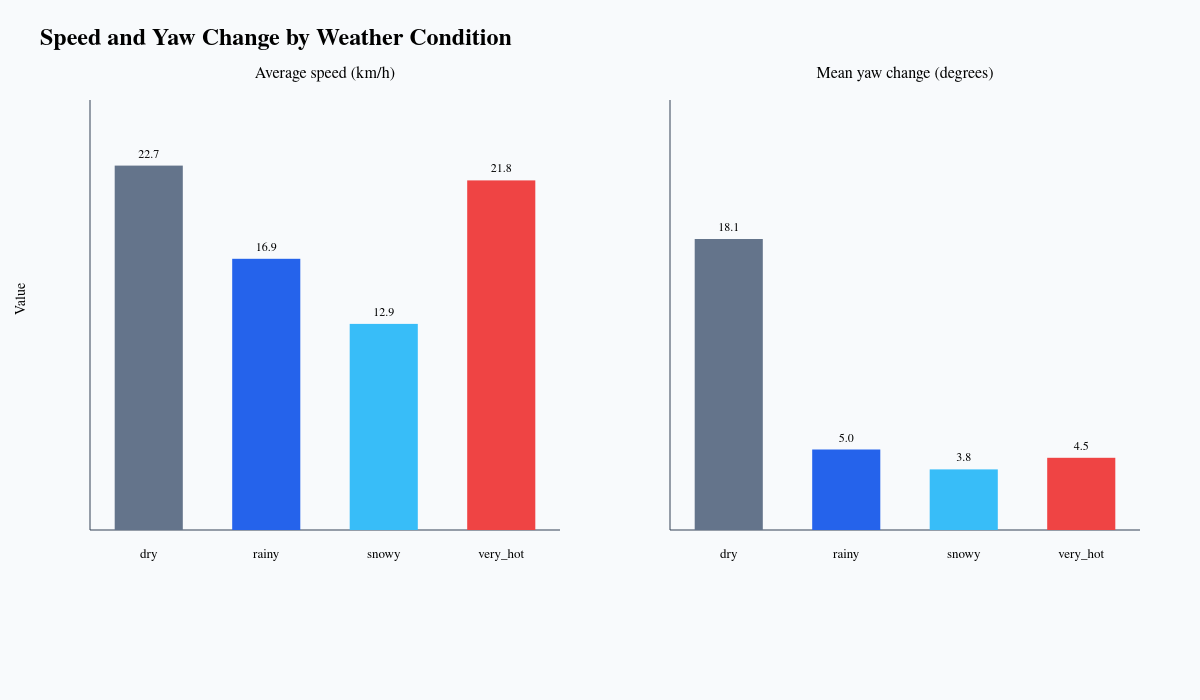

In [ ]:
summary = df.groupby("weather_condition")[["avg_speed_kmh", "mean_yaw_change_deg"]].mean(); summary.plot(kind="bar", figsize=(10, 5), title="Speed and yaw change by weather")
plt.tight_layout(); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q1_1_0f4089a9f2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "In the observed records, rainy and snowy conditions coincide with lower average speeds and smaller mean yaw changes than dry conditions.",
  "question": "How do average speed and mean yaw change vary across dry, rainy, snowy, and very hot conditions?",
  "actionable_insight": "Compare adverse-weather trajectories with the dry-weather baseline using both speed and directional-change distributions.",
  "plot": {
    "plot_type": "bar",
    "title": "Average Speed and Mean Yaw Change by Weather Condition",
    "file": "visualizations/speed_and_yaw_by_weather.svg",
    "description": "The two-panel weather-group comparison shows lower speed and directional change in rainy and snowy records."
  },
  "insight_value": {
    "mean_speed_kmh": {
      "dry": 22.725,
      "rainy": 16.913,
      "snowy": 12.855,
      "very_hot": 21.8
    },
    "mean_yaw_change_deg": {
      "dry": 18.15,
      "rainy": 5.019,
      "snowy": 3.78,
      "very_hot": 4.5
    }
  },
  "insight_type": "factor_relationship",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "weather",
    "temperature",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 2**: How does the user's average trajectory length differ between cold rainy conditions and normal dry conditions?

#### Analysis action

Use the weather-group distance comparison to characterize the observed change in trip length.

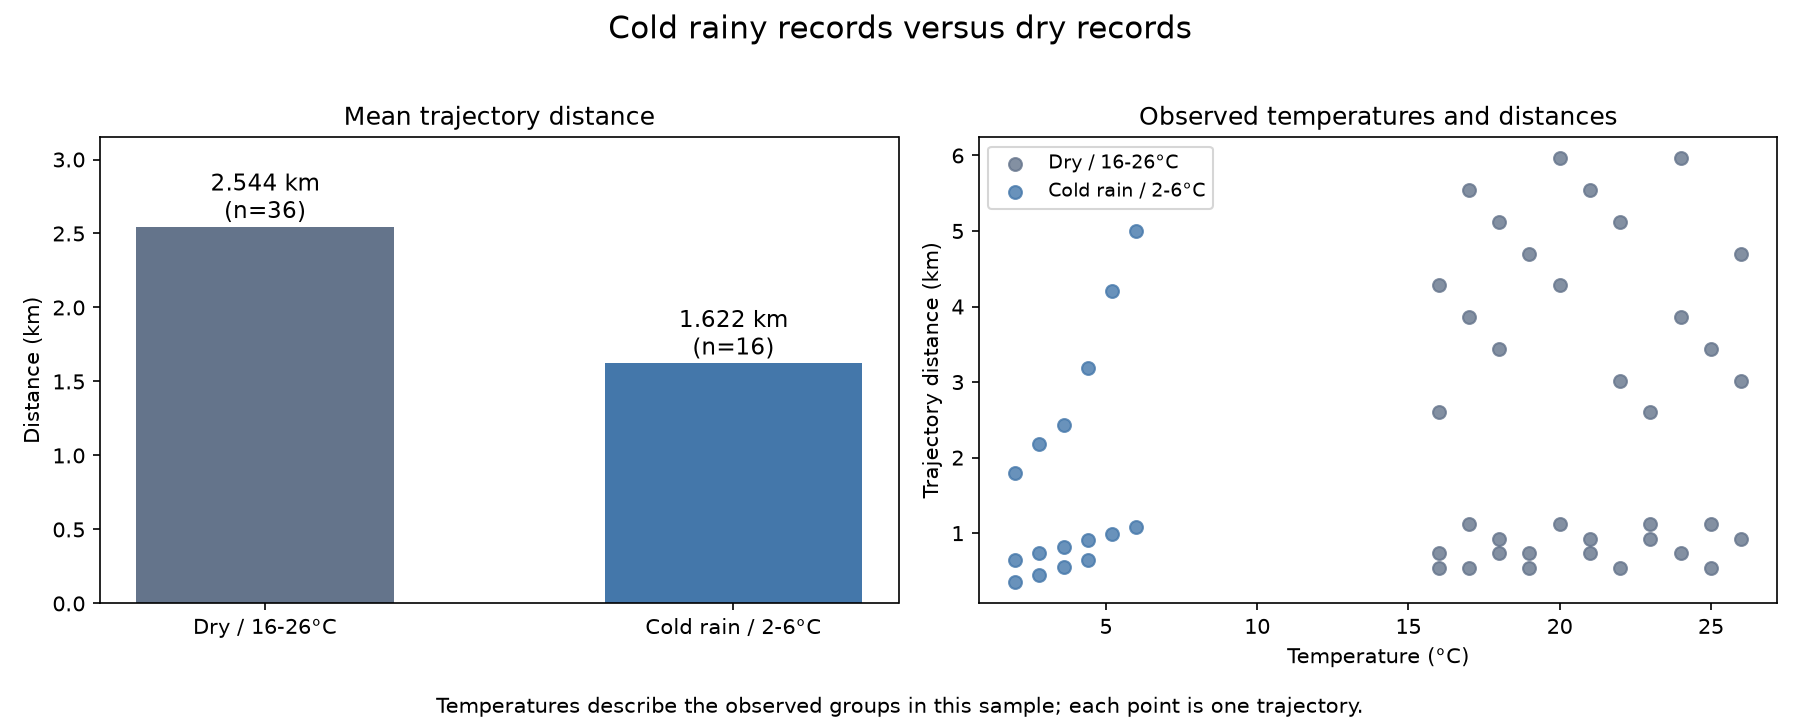

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

cold_rain = df[df.weather_condition.eq("rainy") & df.temperature_2m_c.between(2, 6)]
normal_dry = df[df.weather_condition.eq("dry") & df.temperature_2m_c.between(16, 26)]
groups = [normal_dry, cold_rain]
labels = ["Dry / 16-26°C", "Cold rain / 2-6°C"]
colors = ["#64748b", "#4477aa"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
means = [g.distance_meters.mean()/1000 for g in groups]
axes[0].bar(labels, means, color=colors, width=0.55)
for i, (g, value) in enumerate(zip(groups, means)):
    axes[0].text(i, value+0.06, f"{value:.3f} km\n(n={len(g)})", ha="center", fontsize=11)
axes[0].set(title="Mean trajectory distance", ylabel="Distance (km)", ylim=(0, 3.15))
for g, label, color in zip(groups, labels, colors):
    axes[1].scatter(g.temperature_2m_c, g.distance_meters/1000, color=color, label=label, s=38, alpha=0.8)
axes[1].set(title="Observed temperatures and distances", xlabel="Temperature (°C)", ylabel="Trajectory distance (km)")
axes[1].legend(fontsize=9)
fig.suptitle("Cold rainy records versus dry records", fontsize=15)
fig.text(0.5, 0.01, "Temperatures describe the observed groups in this sample; each point is one trajectory.", ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
plt.show()

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "On cold rainy days, the user's trajectories are shorter on average than on dry days with normal temperatures.",
  "question": "How does the user's average trajectory length differ between cold rainy conditions and normal dry conditions?",
  "actionable_insight": "Use the weather-group distance comparison to characterize the observed change in trip length.",
  "plot": {
    "plot_type": "multi_panel_bar_scatter",
    "title": "Cold Rain versus Dry Conditions: Distance and Temperature",
    "file": "visualizations/distance_by_weather.svg",
    "description": "Left: mean distance and trajectory counts for dry records at 16-26°C and rainy records at 2-6°C. Right: each trajectory plotted by observed temperature and distance."
  },
  "insight_value": {
    "mean_distance_m": {
      "dry": 2544.444,
      "rainy": 1622.312,
      "snowy": 1172.0,
      "very_hot": 1415.0
    },
    "observed_temperature_range_c": {
      "rainy": [
        2,
        6
      ],
      "dry": [
        16,
        26
      ]
    },
    "comparison_counts": {
      "rainy": 16,
      "dry": 36
    }
  },
  "insight_type": "factor_relationship",
  "code": "import matplotlib.pyplot as plt\nimport numpy as np\n\ncold_rain = df[df.weather_condition.eq(\"rainy\") & df.temperature_2m_c.between(2, 6)]\nnormal_dry = df[df.weather_condition.eq(\"dry\") & df.temperature_2m_c.between(16, 26)]\ngroups = [normal_dry, cold_rain]\nlabels = [\"Dry / 16-26°C\", \"Cold rain / 2-6°C\"]\ncolors = [\"#64748b\", \"#4477aa\"]\nfig, axes = plt.subplots(1, 2, figsize=(12, 4.8))\nmeans = [g.distance_meters.mean()/1000 for g in groups]\naxes[0].bar(labels, means, color=colors, width=0.55)\nfor i, (g, value) in enumerate(zip(groups, means)):\n    axes[0].text(i, value+0.06, f\"{value:.3f} km\\n(n={len(g)})\", ha=\"center\", fontsize=11)\naxes[0].set(title=\"Mean trajectory distance\", ylabel=\"Distance (km)\", ylim=(0, 3.15))\nfor g, label, color in zip(groups, labels, colors):\n    axes[1].scatter(g.temperature_2m_c, g.distance_meters/1000, color=color, label=label, s=38, alpha=0.8)\naxes[1].set(title=\"Observed temperatures and distances\", xlabel=\"Temperature (°C)\", ylabel=\"Trajectory distance (km)\")\naxes[1].legend(fontsize=9)\nfig.suptitle(\"Cold rainy records versus dry records\", fontsize=15)\nfig.text(0.5, 0.01, \"Temperatures describe the observed groups in this sample; each point is one trajectory.\", ha=\"center\", fontsize=10)\nfig.tight_layout(rect=(0, 0.04, 1, 0.96))\nplt.show()",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "weather",
    "temperature",
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 3**: How do car and walking activity, as well as trajectory lengths, differ during cold rainy conditions?

#### Analysis action

Read the cold-rain pattern jointly through mode counts and the distribution of car-trajectory distances.

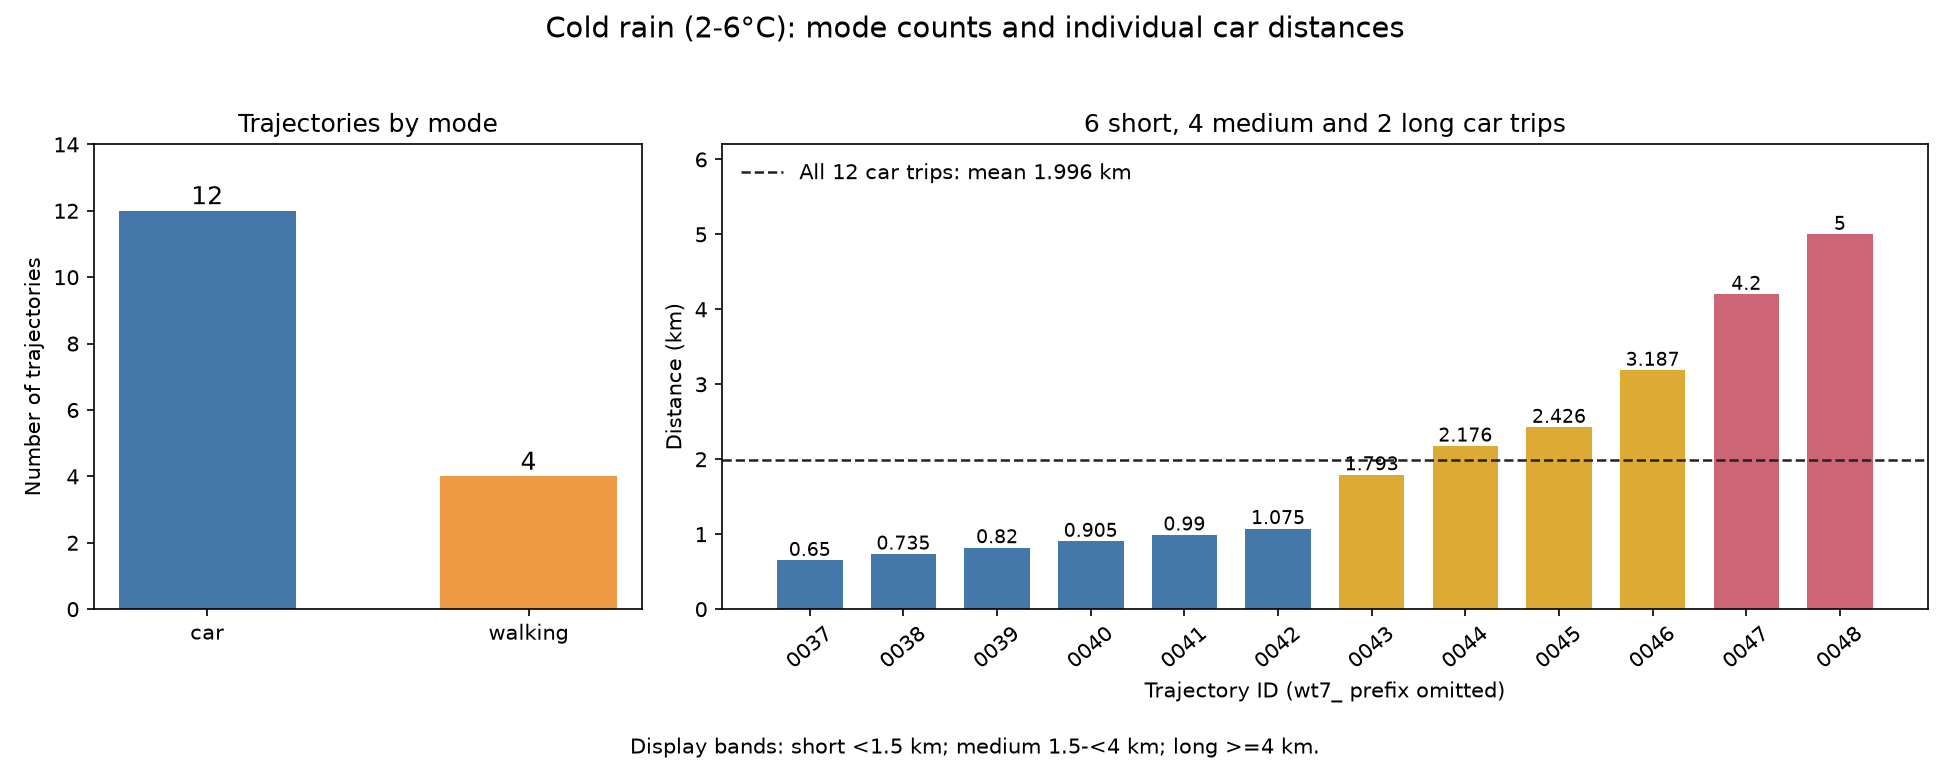

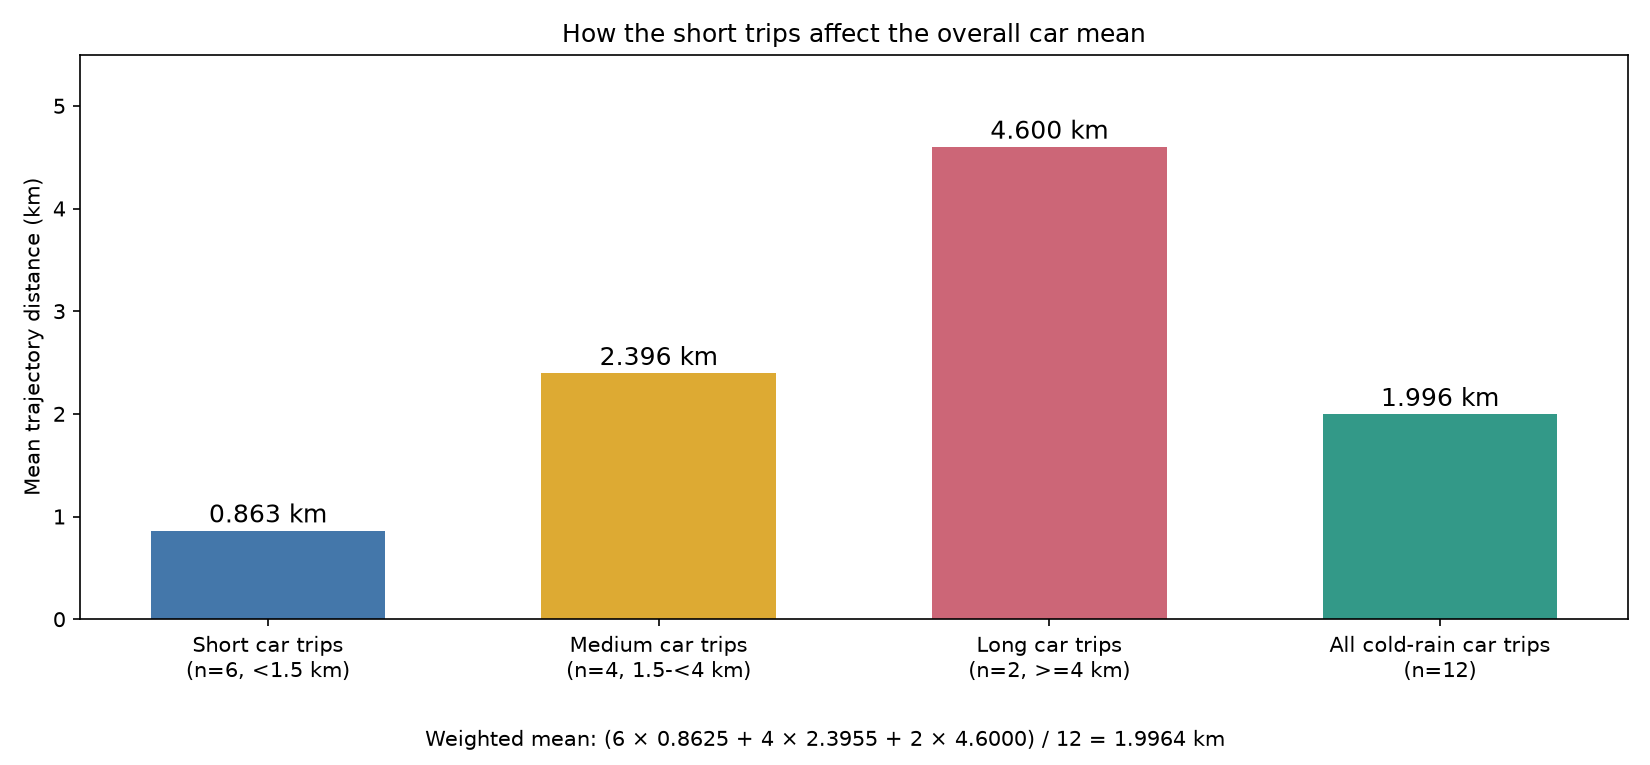

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

cold_rain = df[df.weather_condition.eq("rainy") & df.temperature_2m_c.between(2, 6)]
car = cold_rain[cold_rain.travel_mode.eq("car")].sort_values("distance_meters")
short = car[car.distance_meters < 1500]
medium = car[car.distance_meters.between(1500, 4000, inclusive="left")]
long = car[car.distance_meters >= 4000]
mode_counts = cold_rain.travel_mode.value_counts().reindex(["car", "walking"], fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.1), gridspec_kw={"width_ratios": [1, 2.2]})
axes[0].bar(mode_counts.index, mode_counts.values, color=["#4477aa", "#ee9944"], width=0.55)
for i, value in enumerate(mode_counts):
    axes[0].text(i, value+0.2, str(value), ha="center", fontsize=12)
axes[0].set(title="Trajectories by mode", ylabel="Number of trajectories", ylim=(0, 14))
km = car.distance_meters.to_numpy()/1000
colors = ["#4477aa" if v<1.5 else "#ddaa33" if v<4 else "#cc6677" for v in km]
axes[1].bar(np.arange(len(car)), km, color=colors, width=0.7)
for i, value in enumerate(km):
    axes[1].text(i, value+0.06, f"{value:g}", ha="center", fontsize=9)
axes[1].axhline(km.mean(), color="#222222", ls="--", lw=1.2, label=f"All {len(car)} car trips: mean {km.mean():.3f} km")
axes[1].set_xticks(np.arange(len(car)), [x.removeprefix("wt7_") for x in car.trajectory_id], rotation=40)
axes[1].set(title=f"{len(short)} short, {len(medium)} medium and {len(long)} long car trips", xlabel="Trajectory ID (wt7_ prefix omitted)", ylabel="Distance (km)", ylim=(0, 6.2))
axes[1].legend(loc="upper left", fontsize=10, frameon=False)
fig.suptitle("Cold rain (2-6°C): mode counts and individual car distances", fontsize=14)
fig.text(0.5, 0.015, "Display bands: short <1.5 km; medium 1.5-<4 km; long >=4 km.", ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.05, 1, 0.95))
plt.show()

groups = [short, medium, long, car]
means = [g.distance_meters.mean()/1000 for g in groups]
labels = [f"Short car trips\n(n={len(short)}, <1.5 km)", f"Medium car trips\n(n={len(medium)}, 1.5-<4 km)", f"Long car trips\n(n={len(long)}, >=4 km)", f"All cold-rain car trips\n(n={len(car)})"]
fig, ax = plt.subplots(figsize=(11, 5.1))
ax.bar(labels, means, color=["#4477aa", "#ddaa33", "#cc6677", "#339988"], width=0.6)
for i, value in enumerate(means):
    ax.text(i, value+0.08, f"{value:.3f} km", ha="center", fontsize=12)
ax.set(title="How the short trips affect the overall car mean", ylabel="Mean trajectory distance (km)", ylim=(0, 5.5))
formula = f"Weighted mean: ({len(short)} × {means[0]:.4f} + {len(medium)} × {means[1]:.4f} + {len(long)} × {means[2]:.4f}) / {len(car)} = {means[3]:.4f} km"
fig.text(0.5, 0.025, formula, ha="center", fontsize=10)
fig.tight_layout(rect=(0, 0.075, 1, 1))
plt.show()

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "During cold rainy conditions, car trajectories outnumber walking trajectories. Several very short car trajectories lower the average distance, although a few car trajectories remain long.",
  "question": "How do car and walking activity, as well as trajectory lengths, differ during cold rainy conditions?",
  "actionable_insight": "Read the cold-rain pattern jointly through mode counts and the distribution of car-trajectory distances.",
  "plot": {
    "plot_type": "multi_figure_comparison",
    "title": "Cold Rain: Mode Counts, Individual Car Distances and Mean Composition",
    "file": "visualizations/cold_rain_mode_and_distance.svg",
    "description": "The first figure shows mode counts and every car distance, separating six short, four medium and two long trips. The second displays each distance-band mean and their weighted contribution to the overall car mean.",
    "files": [
      "visualizations/cold_rain_mean_composition.svg"
    ]
  },
  "insight_value": {
    "car_count": 12,
    "walking_count": 4,
    "car_distance_m": [
      650.0,
      735.0,
      820.0,
      905.0,
      990.0,
      1075.0,
      1793.0,
      2176.0,
      2426.0,
      3187.0,
      4200.0,
      5000.0
    ],
    "shorter_car_count": 6,
    "longer_car_count": 6,
    "shorter_car_distance_range_m": [
      650.0,
      1075.0
    ],
    "longer_car_distances_m": [
      1793.0,
      2176.0,
      2426.0,
      3187.0,
      4200.0,
      5000.0
    ],
    "mean_car_distance_m": 1996.4166666666667,
    "shorter_car_mean_distance_m": 862.5,
    "longer_car_mean_distance_m": 3130.3333333333335,
    "display_split_m": 1500,
    "display_split_note": "Plotting bands: short <1500 m; medium 1500 to <4000 m; long >=4000 m. The existing short-trip cutoff is retained.",
    "distance_band_counts": {
      "short": 6,
      "medium": 4,
      "long": 2
    },
    "distance_band_means_m": {
      "short": 862.5,
      "medium": 2395.5,
      "long": 4600.0
    }
  },
  "insight_type": "overall_pattern",
  "code": "import matplotlib.pyplot as plt\nimport numpy as np\n\ncold_rain = df[df.weather_condition.eq(\"rainy\") & df.temperature_2m_c.between(2, 6)]\ncar = cold_rain[cold_rain.travel_mode.eq(\"car\")].sort_values(\"distance_meters\")\nshort = car[car.distance_meters < 1500]\nmedium = car[car.distance_meters.between(1500, 4000, inclusive=\"left\")]\nlong = car[car.distance_meters >= 4000]\nmode_counts = cold_rain.travel_mode.value_counts().reindex([\"car\", \"walking\"], fill_value=0)\nfig, axes = plt.subplots(1, 2, figsize=(13, 5.1), gridspec_kw={\"width_ratios\": [1, 2.2]})\naxes[0].bar(mode_counts.index, mode_counts.values, color=[\"#4477aa\", \"#ee9944\"], width=0.55)\nfor i, value in enumerate(mode_counts):\n    axes[0].text(i, value+0.2, str(value), ha=\"center\", fontsize=12)\naxes[0].set(title=\"Trajectories by mode\", ylabel=\"Number of trajectories\", ylim=(0, 14))\nkm = car.distance_meters.to_numpy()/1000\ncolors = [\"#4477aa\" if v<1.5 else \"#ddaa33\" if v<4 else \"#cc6677\" for v in km]\naxes[1].bar(np.arange(len(car)), km, color=colors, width=0.7)\nfor i, value in enumerate(km):\n    axes[1].text(i, value+0.06, f\"{value:g}\", ha=\"center\", fontsize=9)\naxes[1].axhline(km.mean(), color=\"#222222\", ls=\"--\", lw=1.2, label=f\"All {len(car)} car trips: mean {km.mean():.3f} km\")\naxes[1].set_xticks(np.arange(len(car)), [x.removeprefix(\"wt7_\") for x in car.trajectory_id], rotation=40)\naxes[1].set(title=f\"{len(short)} short, {len(medium)} medium and {len(long)} long car trips\", xlabel=\"Trajectory ID (wt7_ prefix omitted)\", ylabel=\"Distance (km)\", ylim=(0, 6.2))\naxes[1].legend(loc=\"upper left\", fontsize=10, frameon=False)\nfig.suptitle(\"Cold rain (2-6°C): mode counts and individual car distances\", fontsize=14)\nfig.text(0.5, 0.015, \"Display bands: short <1.5 km; medium 1.5-<4 km; long >=4 km.\", ha=\"center\", fontsize=10)\nfig.tight_layout(rect=(0, 0.05, 1, 0.95))\nplt.show()\n\ngroups = [short, medium, long, car]\nmeans = [g.distance_meters.mean()/1000 for g in groups]\nlabels = [f\"Short car trips\\n(n={len(short)}, <1.5 km)\", f\"Medium car trips\\n(n={len(medium)}, 1.5-<4 km)\", f\"Long car trips\\n(n={len(long)}, >=4 km)\", f\"All cold-rain car trips\\n(n={len(car)})\"]\nfig, ax = plt.subplots(figsize=(11, 5.1))\nax.bar(labels, means, color=[\"#4477aa\", \"#ddaa33\", \"#cc6677\", \"#339988\"], width=0.6)\nfor i, value in enumerate(means):\n    ax.text(i, value+0.08, f\"{value:.3f} km\", ha=\"center\", fontsize=12)\nax.set(title=\"How the short trips affect the overall car mean\", ylabel=\"Mean trajectory distance (km)\", ylim=(0, 5.5))\nformula = f\"Weighted mean: ({len(short)} × {means[0]:.4f} + {len(medium)} × {means[1]:.4f} + {len(long)} × {means[2]:.4f}) / {len(car)} = {means[3]:.4f} km\"\nfig.text(0.5, 0.025, formula, ha=\"center\", fontsize=10)\nfig.tight_layout(rect=(0, 0.075, 1, 1))\nplt.show()",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "weather",
    "temperature",
    "transport_mode",
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 4**: How frequently does the user travel in car and walking modes when the temperature exceeds 35°C?

#### Analysis action

Compare the number of very-hot-weather trajectories with the much larger set of trajectories in other weather conditions.

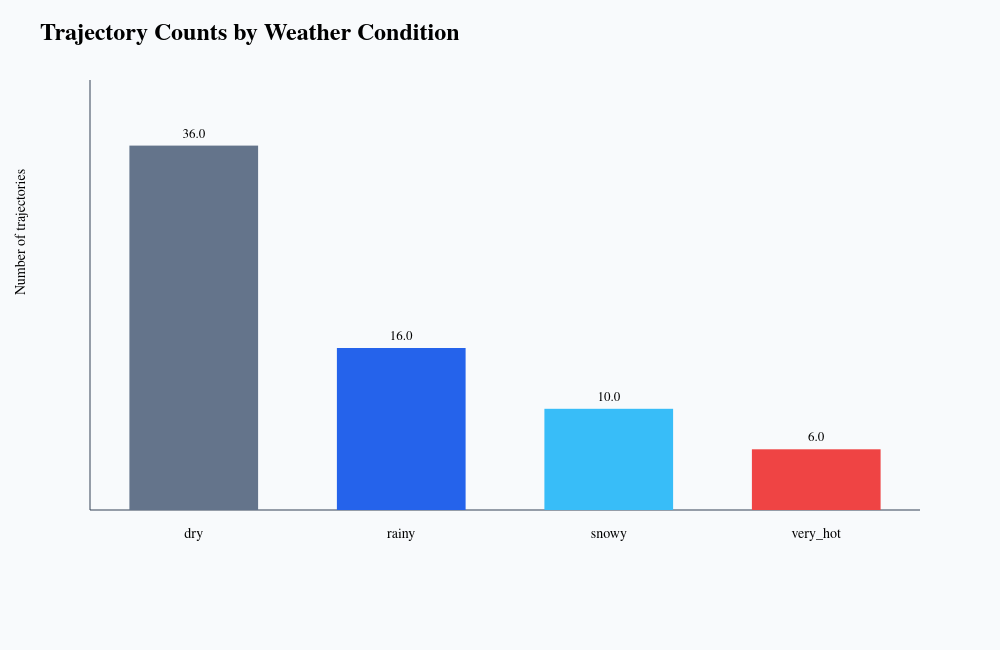

In [ ]:
df.assign(very_hot=df["temperature_2m_c"] > 35).groupby("very_hot").size().plot(kind="bar", title="Trajectory counts by very-hot condition"); plt.tight_layout(); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q4_1_fa461b77ea.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "On very hot days above 35°C, the user generates only a few trajectories across both car and walking modes.",
  "question": "How frequently does the user travel in car and walking modes when the temperature exceeds 35°C?",
  "actionable_insight": "Compare the number of very-hot-weather trajectories with the much larger set of trajectories in other weather conditions.",
  "plot": {
    "plot_type": "bar",
    "title": "Trajectory Counts by Weather Condition",
    "file": "visualizations/trajectory_counts_by_weather.svg",
    "description": "The weather-group counts identify the sparse very-hot-weather activity."
  },
  "insight_value": {
    "very_hot_trajectory_count": 6,
    "very_hot_modes": [
      "car",
      "walking"
    ]
  },
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "temperature",
    "transport_mode",
    "trajectory_id",
    "weather"
  ]
}

### **Question 5**: How does route directness in very-hot-weather car trajectories compare with the user's normal car trajectories?

#### Analysis action

Compare the very-hot-weather car routes with the normal car baseline using route-indirectness scores.

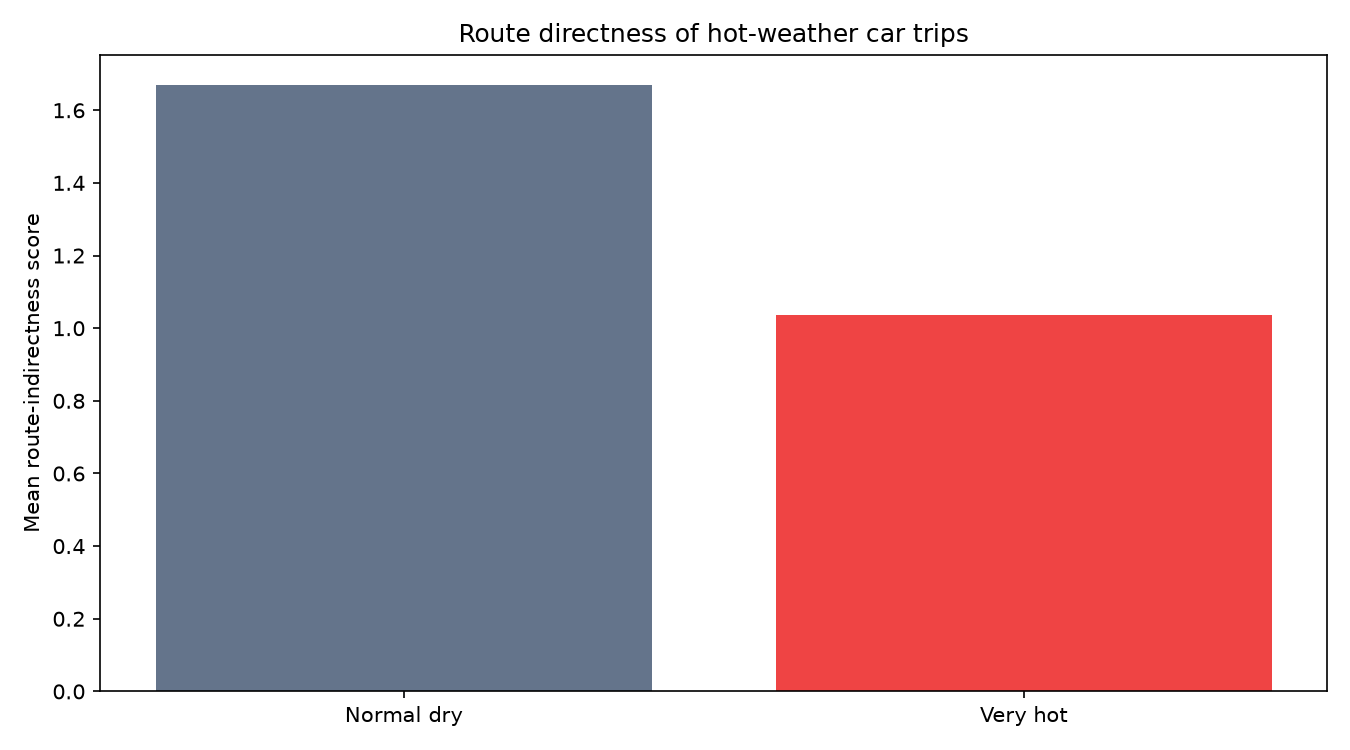

In [ ]:
normal = df[df.travel_mode.eq("car") & df.weather_condition.eq("dry")]
hot = df[df.travel_mode.eq("car") & df.weather_condition.eq("very_hot")]
pd.Series({"Normal dry": normal.detour_score.mean(), "Very hot": hot.detour_score.mean()}).plot(kind="bar", title="Route directness of hot-weather car trips")
plt.ylabel("Mean route-indirectness score")
plt.tight_layout()
plt.show()
from IPython.display import Image, display
display(Image(filename="notebook_plots/q5_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "The few car trajectories recorded above 35°C are more direct, with lower route-indirectness scores than the user's normal car trajectories.",
  "question": "How does route directness in very-hot-weather car trajectories compare with the user's normal car trajectories?",
  "actionable_insight": "Compare the very-hot-weather car routes with the normal car baseline using route-indirectness scores.",
  "plot": {
    "plot_type": "bar",
    "title": "Route Directness of Hot-Weather Car Trips",
    "file": "visualizations/hot_car_directness.svg",
    "description": "The comparison shows lower route-indirectness scores for the few very-hot-weather car trajectories."
  },
  "insight_value": {
    "normal_car_mean_detour": 1.67,
    "very_hot_car_mean_detour": 1.037
  },
  "insight_type": "factor_relationship",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "temperature",
    "transport_mode",
    "gps_position",
    "trajectory_id",
    "weather"
  ]
}

### Summary of Findings (Flag 7)

The user's observed travel behavior varies across weather conditions: rainy and snowy records have lower speeds and smaller yaw changes, cold rainy trips are shorter and dominated by car travel, very hot days contain few trajectories in either mode, and the few hot-weather car trips are more direct than normal car trips.